# Water-biomass dynamics autonomous model

We consider a dynamical system describing the interaction between water $e(t)$ available in the root zone and a given crop (biomass) $z(t)$, under a given water threshold $e_{\max}$:

$$
\begin{cases}
\displaystyle \dot{e}(t) = -\alpha e(t) - \beta e(t)\left(1-\frac{e(t)}{e_{\max}}\right)_{+} z(t) + u,\\[2mm]
\displaystyle \dot{z}(t) = -\gamma z(t) + \delta e(t)\left(1-\frac{e(t)}{e_{\max}}\right)_{+} z(t)
\end{cases}
$$

with initial conditions $e(0)=e_{0}$ and $z(0)=z_{0}$ where $(a)_+ := \max(a, 0)$ . 
More precisely:

- $\alpha$ is the water loss coefficient (evaporation, runoff, drainage). 
- $\gamma$ is the natural biomass loss coefficient during growth.
- $\beta$ is the plant water uptake coefficient during growth.
- $\delta$ is the biomass production coefficient associated with water consumption. 
- $e_{max}$ is a water threshold above which the plant ceases to take up water, with a risk of root asphyxia or senescence. Thus,  $\left(1-\frac{e(t)}{e_{\max}}\right)_{+}$ means that if $ e(t) < e_{max}$ then the plant continues to take up water for growth, with an effet
$\beta e(t) \left(1-\frac{e(t)}{e_{max}}\right)z(t)$ on the water state. However, if $ e(t) \geq e_{max}$ then the plant no longer takes up water and therefore $\left(1-\frac{e(t)}{e_{\max}}\right)_{+}=0$. 
- $u$ is the combined input of rainwater and irrigation water.

## 1. Modules importation

Install these packages if they are not installed on the Python distribution.

Uncomment the lignes and run the cell to proced to the installation.

In [1]:
# %pip install numpy
# %pip install matplotlib
# %pip install scipy

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

## 2. System definition and resolution functions

### 2.1. System definition

In [3]:
def system(v, emax, u, alpha, beta, gamma, delta):
    e, z = v
    interaction = e * max(1.0 - e / emax, 0.0) * z
    de = -alpha * e - beta * interaction + u
    dz = -gamma * z + delta * interaction
    return np.array([de, dz], dtype=float)

### 2.2. Numerical solver

In [4]:
def simulate(e0, z0, emax, u, alpha, beta, gamma, delta, T, n):
    y0 = (e0, z0)
    t_eval = np.linspace(0.0, T, n)
    sol = solve_ivp(
        fun=lambda t, v : system(v, emax, u, alpha, beta, gamma, delta),
        t_span=(0.0, T),
        y0=np.asarray(y0, dtype=float),
        t_eval=t_eval,
        method="RK45",
        rtol=1e-8,
        atol=1e-10,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

### 2.3. Interaction factor

In the active region $0<e<e_{\max}(t)$, the interaction can be written as
$$
\mathcal{I}(t,e,z) = g_t(e) z
$$

with 

$$
g_t(e) = e\left(1 - \frac{e}{e_{\max}(t)}\right)
$$

the interaction based on the water stock $e$ only.

For fixed $t$ and $z$, the derivative of $\mathcal{I}(t,e,z)$ reads 

$$
\frac{\partial \mathcal{I}}{\partial e}(t,e,z) = \left(1-\frac{2e}{e_{\max}(t)}\right)z
$$

It reaches its maximum for

$$
e^c=\frac{e_{\max}}{2},
$$

with the value

$$
\mathcal{I}(t, e^c, z) = \frac{e_{\max}^2 z}{4}.
$$

Three regimes are distinguished for the interaction with respect to the water component:

- $0<e<\frac{e_{\max}(t)}{2}$: the interaction intensity increases with $e$;
- $\frac{e_{\max}(t)}{2}<e<e_{\max}(t)$: the interaction intensity decreases with $e$; 
- $e\geq e_{\max}(t)$: the interaction is null.

Howether, the interaction is linear and strictly increasing in $z$ only when $0 < e < e_{\max}(t)$.

In [5]:
def interaction_on_e(t_eval, e):
    inter = []
    for i, t in enumerate(t_eval):
        e_value = e[i]
        inter.append(e_value * np.maximum(1.0 - e_value / emax, 0.0))
    return inter

In [6]:
def interaction_global(t_eval, e, z):
    inter = []
    for i, t in enumerate(t_eval):
        e_value = e[i]
        z_value = z[i]
        inter.append(e_value * np.maximum(1.0 - e_value / emax, 0.0) * z_value)
    return inter

### 2.3. Equilibrium points

An equilibrium point $(e^\star,z^\star)$ satisfies
$$
\begin{cases} 
\dot{e}^\star = -\alpha e^\star - \beta \mathcal{I} (t, e^\star, z^\star) + u = 0, \\[2mm]
\dot{z}^\star = -\gamma e^\star + \delta \mathcal{I}(t, e^\star, z^\star) =0.
\end{cases}
$$

$\bullet$ On the boundary $z^\star=0$, the assumption $\mathcal{I}(t, e, 0)=0$ leads to

$$
e^\star=-\frac{u}{\alpha}, \quad \alpha\neq0.
$$

- If $u=0$, then $e^\star=0$. Thus, the origin $(0,0)$ is a boundary equilibrium (extinction of both components) regardless of $\alpha$. 
- If $u>0$, the point $(-\frac{u}{\alpha}, 0)$ is a boundary equilibrium representing persistence of water and extinction of the biomass.

$\bullet$ On the boundary $e^\star=0$, the relation $\mathcal{I}(t, 0, z)=0$ gives

$$
u=0 \quad \text{and} \quad -\gamma z^\star=0.
$$

Thus, for $\gamma \neq 0$, the origin $(0,0)$ constitutes the only boundary equilibrium only when $u=0$.

$\bullet$ For interior equilibria $e^\star>0$ and $z^\star>0$, one obtains from the second equation

$$
-\gamma + \delta e^\star\left(1-\frac{e^\star}{e_{\max}}\right)=0.
$$

that yields to the equation

$$
(e^\star)^2-e_{\max}e^\star+\frac{\gamma e_{\max}}{\delta}=0.
$$

whose discriminant is

$$
\Delta=e_{\max}\left(e_{\max}-\frac{4\gamma}{\delta}\right).
$$

Then,

- if $\Delta<0$, there is any interior equilibrium;
- if $\Delta=0$, there is one critical interior equilibrium;
- ii $\Delta>0$, there are two critical interior equilibria.


**Case $\Delta=0$, i.e $e^c_{\max}=\frac{4\gamma}{\delta}$**:

We obtain
$$
e^{\star} = \frac{e_{\max}}{2}.
$$
This corresponds to the critical threshold of the interaction factor $\mathcal{I} (t, e^\star, z^\star)$ considered above.

**Case $\Delta>0$, i.e $e^c_{\max}>\frac{4\gamma}{\delta}$**:

We obtient

$$
e_1^\star = \frac{e_{\max} - \sqrt{\Delta}}{2}, \qquad
e_2^\star = \frac{e_{\max} + \sqrt{\Delta}}{2}.
$$

**Value of $z^{\star}$**:

- For $u=0$,
$$
z^\star = \frac{-\alpha \delta}{\beta \gamma} e^\star.
$$

- For $u\neq0$,
$$
z^\star = \frac{\delta}{\beta \gamma} (-\alpha e^\star + u).
$$

In [7]:
def extinction_equilibria(u, alpha):
    e_star = u / alpha
    z_star = 0.0
    return (e_star, z_star)

def coexistence_equilibria(emax, u, alpha, beta, gamma, delta):
    disc = emax**2 - 4.0 * gamma * emax / delta
    
    if disc == 0:
        estar = emax / 2.0
        zstar = (-alpha * estar + u) * delta / (beta * gamma)
        return [
            (estar, zstar),
            (estar, zstar)
        ]
    elif disc > 0:
        estar1 = (emax - np.sqrt(disc)) / 2.0
        estar2 = (emax + np.sqrt(disc)) / 2.0
        zstar1 = (-alpha * estar1 + u) * delta / (beta * gamma)
        zstar2 = (-alpha * estar2 + u) * delta / (beta * gamma)
        return [
            (estar1, zstar1),
            (estar2, zstar2)
        ]
    
    return [(None, None), (None, None)]

## 3. Simulation

### 3.1. Model parameters

#### Time horizon

In [8]:
T = 30 * 4 + 10
n = T * 5
t_eval = np.linspace(0.0, T, n)

#### Coefficients

In [9]:
alpha = 0.15
beta = 0.1
gamma = 0.07
delta = 0.06

#### Water threshold and input

In [10]:
emax = 11
u = 1.9

#### Referencial initial condition

In [11]:
e0_ref = 2
z0_ref = 1

### 3.2. Resolution

In [12]:
sol = simulate(e0_ref, z0_ref, emax, u, alpha, beta, gamma, delta, T, n)

### 3.3. Evolution of e & z

#### Compared time evolution of $e(.)$ and $z(.)$

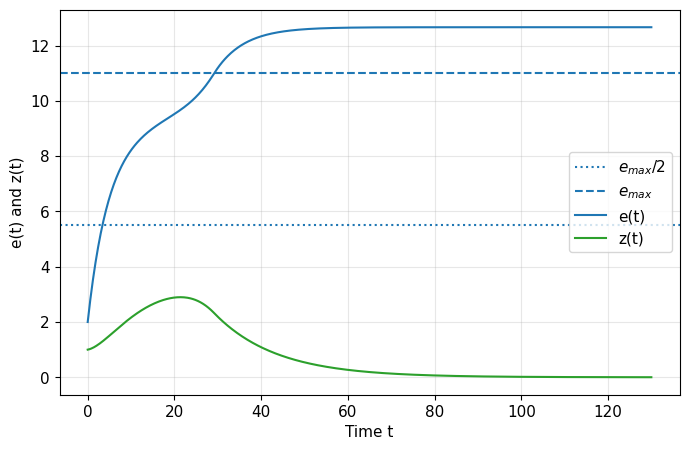

In [13]:
plt.axhline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
plt.axhline(emax, linestyle="--", label=r"$e_{max}$")
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
plt.xlabel("Time t")
plt.ylabel("e(t) and z(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

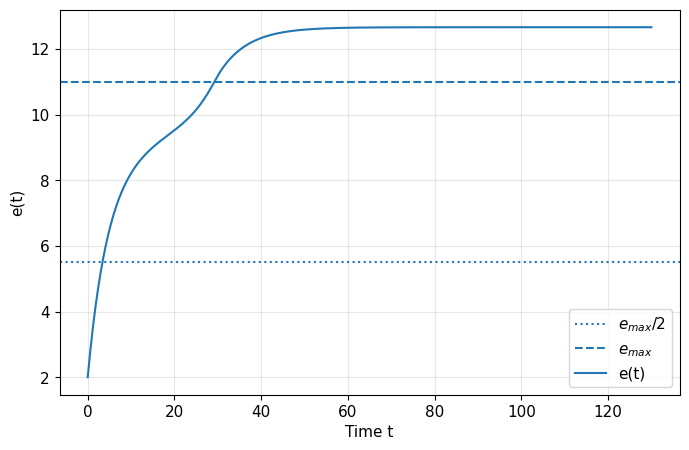

In [14]:
plt.axhline(emax / 2, linestyle=":", label=r"$e_{max}/2$", color='tab:blue')
plt.axhline(emax, linestyle="--", label=r"$e_{max}$", color='tab:blue')
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.xlabel("Time t")
plt.ylabel("e(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

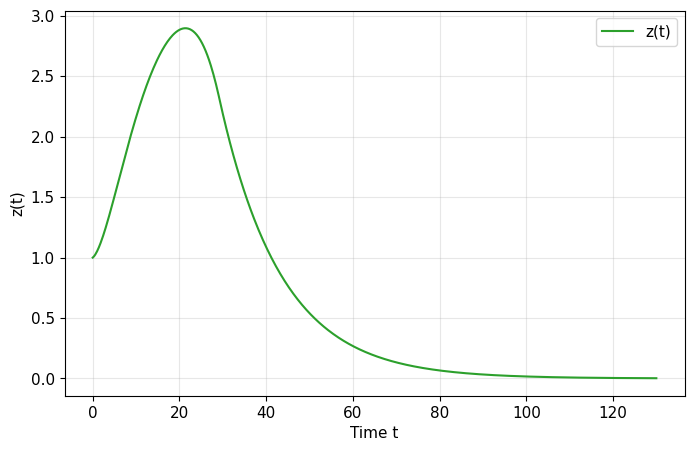

In [15]:
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
plt.xlabel("Time t")
plt.ylabel("z(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

#### Phase portraits

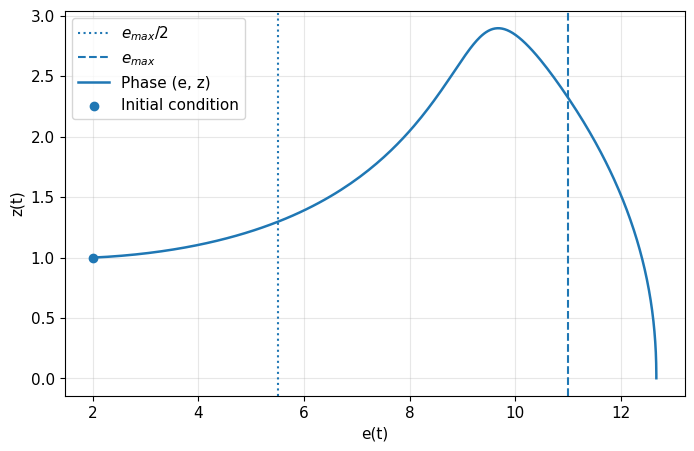

In [16]:
plt.axvline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
plt.axvline(emax, linestyle="--", label=r"$e_{max}$")
plt.plot(sol.y[0], sol.y[1], linewidth=1.8, label="Phase (e, z)")
plt.scatter([e0_ref], [z0_ref], label="Initial condition", zorder=3)
plt.xlabel("e(t)")
plt.ylabel("z(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

#### Equilibria

In [17]:
ex_eq = extinction_equilibria(u, alpha)
ex_eq

(12.666666666666666, 0.0)

In [18]:
co_eqs = coexistence_equilibria(emax, u, alpha, beta, gamma, delta)
co_eqs

[(1.3266719914836953, 14.579993153806672),
 (9.673328008516304, 3.8485782747647512)]

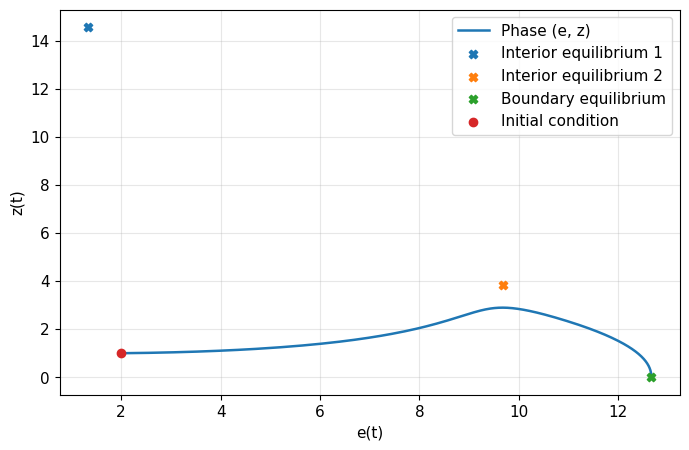

In [19]:
# plt.axvline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
# plt.axvline(emax, linestyle="--", label=r"$e_{max}$")

plt.plot(sol.y[0], sol.y[1], linewidth=1.8, label="Phase (e, z)")

plt.scatter([co_eqs[0][0]], [co_eqs[0][1]], marker='X', label="Interior equilibrium 1", zorder=3)
plt.scatter([co_eqs[1][0]], [co_eqs[1][1]], marker='X', label="Interior equilibrium 2", zorder=3)
plt.scatter([ex_eq[0]], [ex_eq[1]], marker='X', label="Boundary equilibrium", zorder=3)

plt.scatter([e0_ref], [z0_ref], label="Initial condition", zorder=3)

plt.xlabel("e(t)")
plt.ylabel("z(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

#### Interaction factor

In [20]:
g_interaction_values = interaction_global(t_eval, sol.y[0], sol.y[1])
interaction_values = interaction_on_e(t_eval, sol.y[0])

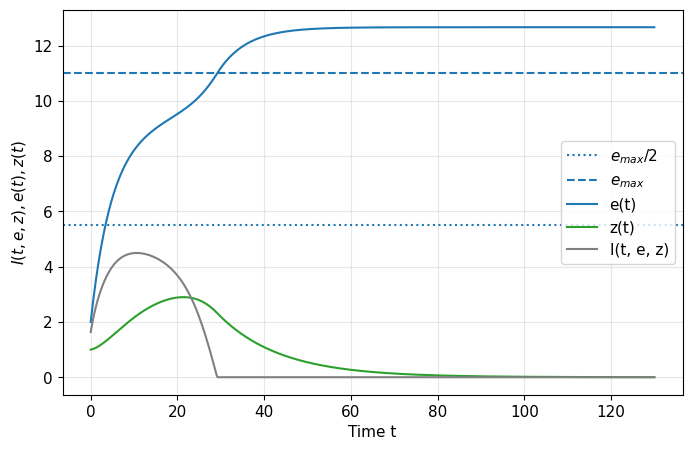

In [21]:
plt.axhline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
plt.axhline(emax, linestyle="--", label=r"$e_{max}$")
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray')
# plt.plot(t_eval, interaction_values, label='I(t, e, 1)', color='gray', linestyle='--')
plt.xlabel("Time t")
plt.ylabel(r"$I(t, e, z), e(t), z(t)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

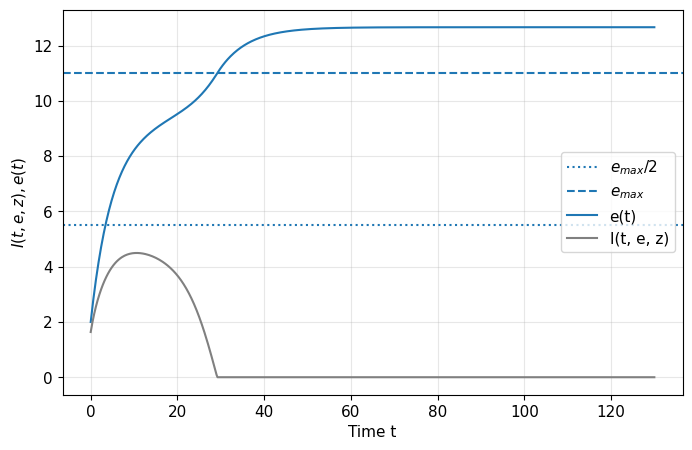

In [22]:
plt.axhline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
plt.axhline(emax, linestyle="--", label=r"$e_{max}$")
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray')
# plt.plot(t_eval, interaction_values, label='I(t, e, 1)', color='gray', linestyle='--')
plt.xlabel("Time t")
plt.ylabel(r"$I(t, e, z), e(t)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

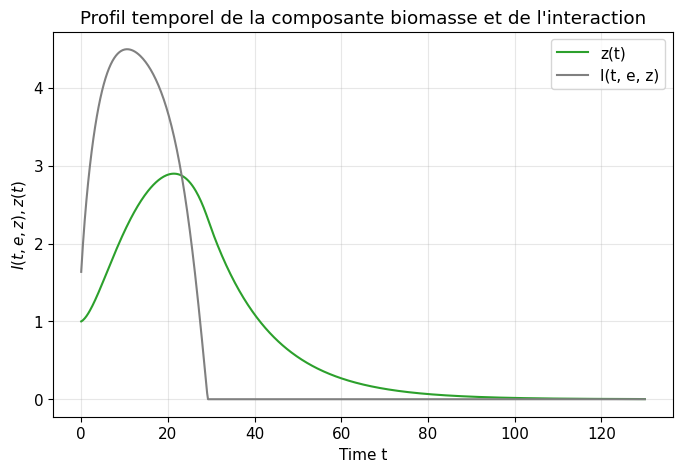

In [23]:
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray')
# plt.plot(t_eval, interaction_values, label='I(t, e, 1)', color='gray', linestyle='--')
plt.xlabel("Time t")
plt.ylabel(r"$I(t, e, z), z(t)$")
plt.title(r"Profil temporel de la composante biomasse et de l'interaction")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

In [24]:
ti_emax = np.argmax(sol.y[0] >= emax)
ti_emax_sur2 = np.argmax(sol.y[0] >= emax / 2)
print(f"Time t where e(t) reaches emax: {t_eval[ti_emax]}")
print(f"Time t where e(t) reaches emax/2: {t_eval[ti_emax_sur2]}")

Time t where e(t) reaches emax: 29.244992295839754
Time t where e(t) reaches emax/2: 3.4052388289676423


In [25]:
zmax = np.max(sol.y[1])
ti_zmax = np.argmax(sol.y[1] == zmax)
print(f"Maximum of z(t): {zmax}")
print(f"Time t whiere z(t) reaches z_max : {t_eval[ti_zmax]}")

Maximum of z(t): 2.897934832218867
Time t whiere z(t) reaches z_max : 21.432973805855163


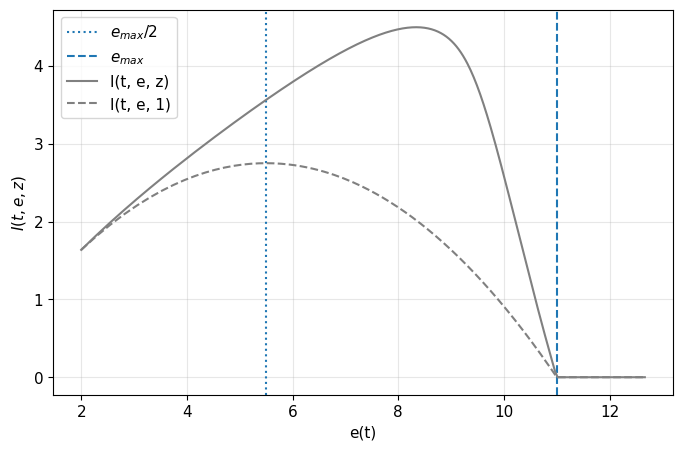

In [26]:
plt.axvline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
plt.axvline(emax, linestyle="--", label=r"$e_{max}$")
plt.plot(sol.y[0], g_interaction_values, label='I(t, e, z)', color='gray')
plt.plot(sol.y[0], interaction_values, label='I(t, e, 1)', color='gray', linestyle='--')
plt.xlabel("e(t)")
plt.ylabel(r"$I(t, e, z)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

In [27]:
ti_nulle_interaction = np.argmax(np.array(g_interaction_values) == 0)
print(f"Time i où I(t,e,z)=0: {ti_nulle_interaction}")
print(f"Time t où I(t,e,z)=0: {t_eval[ti_nulle_interaction]}")

Time i où I(t,e,z)=0: 146
Time t où I(t,e,z)=0: 29.244992295839754


In [28]:
print(f"Time TM2 : {t_eval[ti_nulle_interaction+10]}")

Time TM2 : 31.248073959938367


In [29]:
print(f"z(TM2) : {sol.y[1][ti_nulle_interaction+10]}")

z(TM2) : 2.007597127148989


### 3.4. Sensibility to the initial conditions

#### $e_0$ and $z_0$ sensibility

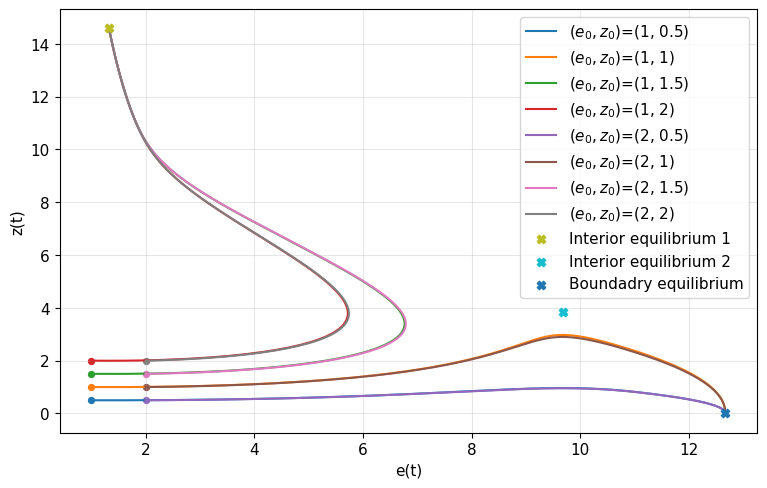

In [30]:
initial_conditions = [
    (1, 0.5),
    (1, 1),
    (1, 1.5),
    (1, 2),
    (2, 0.5), 
    (2, 1), 
    (2, 1.5), 
    (2, 2), 
]

plt.figure(figsize=(9, 5.5))

for y0 in initial_conditions:
    s = simulate(y0[0], y0[1], emax, u, alpha, beta, gamma, delta, T, n)
    plt.plot(s.y[0], s.y[1], label=r"$(e_0, z_0)$="+str(y0))
    plt.scatter([y0[0]],[y0[1]], s=18)

plt.scatter([co_eqs[0][0]], [co_eqs[0][1]], marker='X', label="Interior equilibrium 1", zorder=3)
plt.scatter([co_eqs[1][0]], [co_eqs[1][1]], marker='X', label="Interior equilibrium 2", zorder=3)
plt.scatter([ex_eq[0]], [ex_eq[1]], marker='X', label="Boundadry equilibrium", zorder=3)
# plt.axvline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
# plt.axvline(emax, linestyle="--", label=r"$e_{max}$")

plt.xlabel("e(t)"); plt.ylabel("z(t)")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

#### $z_0$ sensibility

In [31]:
def z0_sensibility(e0_ref, z0_values):
    for z0 in z0_values:
        s = simulate(e0_ref, z0, emax, u, alpha, beta, gamma, delta, T, n)
        plt.plot(s.y[0], s.y[1], label=r"$z_0$="+str(z0))
        plt.scatter([e0_ref],[z0], s=18)

    plt.scatter([co_eqs[0][0]], [co_eqs[0][1]], marker='X', label="Interior equilibrium 1", zorder=3)
    plt.scatter([co_eqs[1][0]], [co_eqs[1][1]], marker='X', label="Interior equilibrium 2", zorder=3)
    plt.scatter([ex_eq[0]], [ex_eq[1]], marker='X', label="Boundadry equilibrium", zorder=3)
    # plt.axvline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
    # plt.axvline(emax, linestyle="--", label=r"$e_{max}$")

    plt.xlabel("e(t)"); plt.ylabel("z(t)")
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.show()

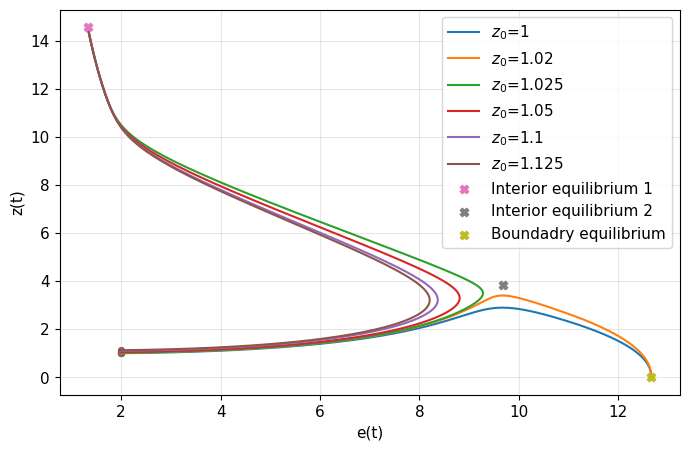

In [32]:
e0_ref = 2
# z0_values = [0.5, 0.75, 1, 1.5, 1.75, 2, 4]
# z0_values = [1, 1.125, 1.25, 1.375, 1.5]
z0_values = [1, 1.02, 1.025, 1.05, 1.1, 1.125]
z0_sensibility(e0_ref, z0_values)

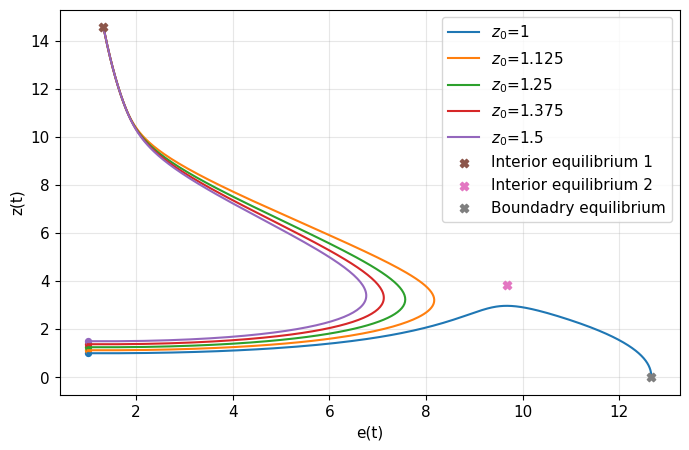

In [33]:
e0_ref = 1
z0_values = [1, 1.125, 1.25, 1.375, 1.5]
z0_sensibility(e0_ref, z0_values)

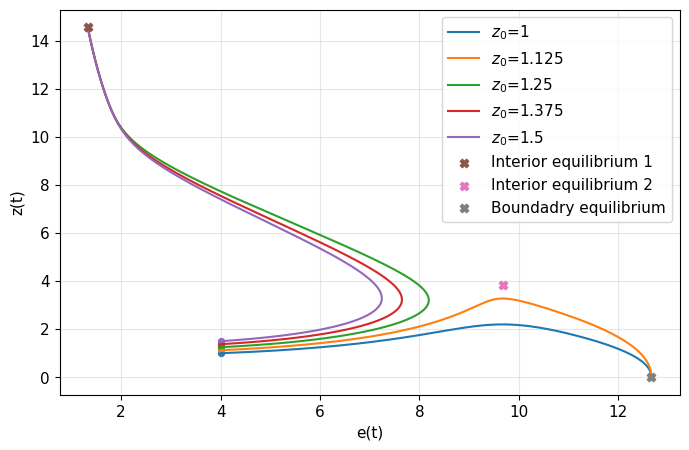

In [34]:
e0_ref = 4
z0_values = [1, 1.125, 1.25, 1.375, 1.5]
z0_sensibility(e0_ref, z0_values)

#### $e_0$ sensibility

In [35]:
def e0_sensibility(z0_ref, e0_values):
    for e0 in e0_values:
        s = simulate(e0, z0_ref, emax, u, alpha, beta, gamma, delta, T, n)
        plt.plot(s.y[0], s.y[1], label=r"$e_0$="+str(e0))
        plt.scatter([e0],[z0_ref], s=18)

    plt.scatter([co_eqs[0][0]], [co_eqs[0][1]], marker='X', label="Interior equilibrium 1", zorder=3)
    plt.scatter([co_eqs[1][0]], [co_eqs[1][1]], marker='X', label="Interior equilibrium 2", zorder=3)
    plt.scatter([ex_eq[0]], [ex_eq[1]], marker='X', label="Boundadry equilibrium", zorder=3)
    # plt.axvline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
    # plt.axvline(emax, linestyle="--", label=r"$e_{max}$")

    plt.xlabel("e(t)"); plt.ylabel("z(t)")
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.show()

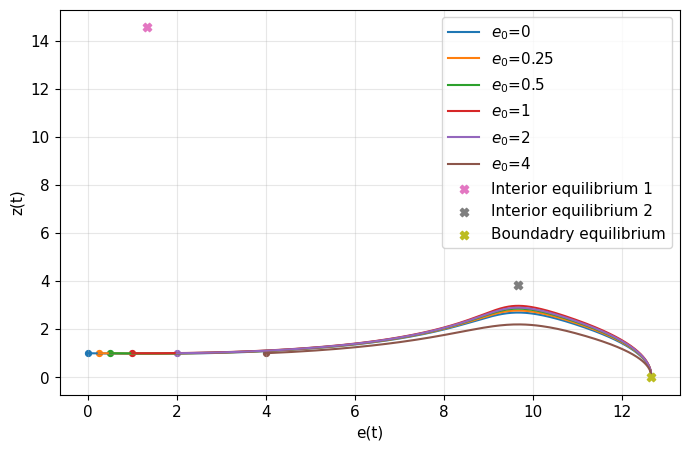

In [36]:
z0_ref = 1
e0_values = [0, 0.25, 0.5, 1, 2, 4]
e0_sensibility(z0_ref, e0_values)

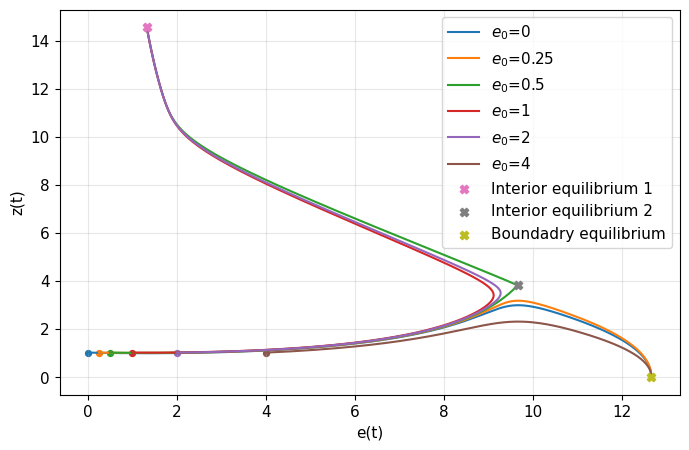

In [37]:
z0_ref = 1.025 # 1.0249
e0_values = [0, 0.25, 0.5, 1, 2, 4]
e0_sensibility(z0_ref, e0_values)

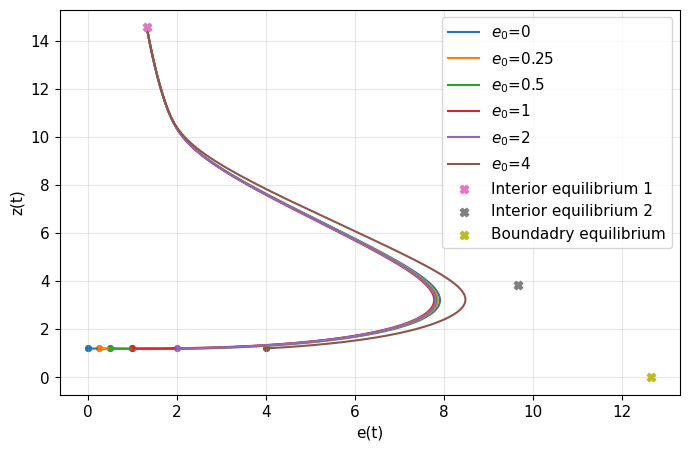

In [38]:
z0_ref = 1.2
e0_values = [0, 0.25, 0.5, 1, 2, 4]
e0_sensibility(z0_ref, e0_values)

### 3.5. Sensibility to input water

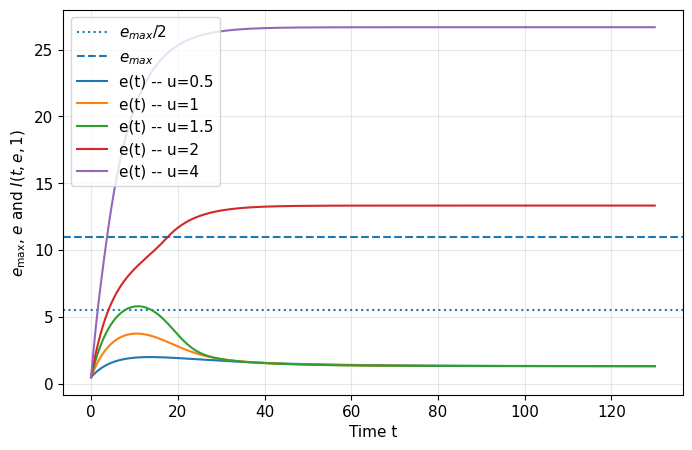

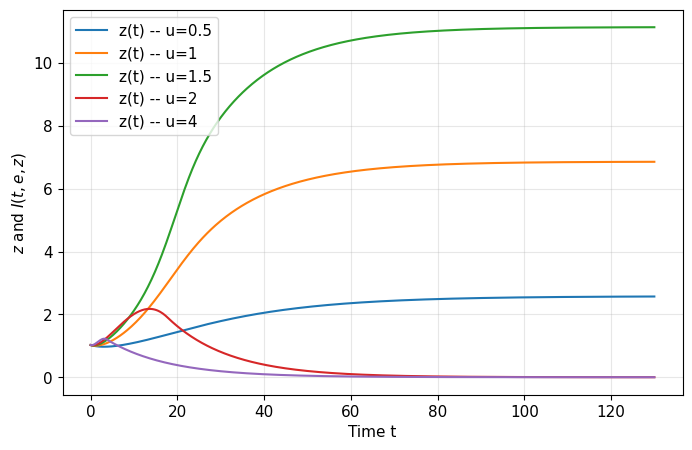

In [39]:
e0_critical = 0.5
z0_critical = 1.025
u_values = [0.5, 1, 1.5, 2, 4]   

results = []

for u in u_values:
    sol = simulate(e0_critical, z0_critical, emax, u, alpha, beta, gamma, delta, T, n)
    results.append(sol)

plt.axhline(emax / 2, linestyle=":", label=r"$e_{max}/2$")
plt.axhline(emax, linestyle="--", label=r"$e_{max}$")

for i, sol in enumerate(results):
    plt.plot(sol.t, sol.y[0], label=f"e(t) -- u={u_values[i]}")
plt.xlabel("Time t")
plt.ylabel(r"$e_{\max}$, $e$ and $I(t, e, 1)$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

for i, sol in enumerate(results):
    plt.plot(sol.t, sol.y[1], label=f"z(t) -- u={u_values[i]}")
plt.xlabel("Time t")
plt.ylabel(r"$z$ and $I(t, e, z)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()